In [1]:
import pandas as pd
print("Pandas library imported successfully.")

Pandas library imported successfully.


In [2]:
from sklearn.datasets import load_iris

# Load the iris dataset
iris = load_iris()

df_iris = pd.DataFrame(data=iris.data, columns = iris.feature_names)

In [5]:
# Add the target variable (species) to the DataFrame
df_iris['species'] = iris.target_names[iris.target]

print("First 5 rows of the Iris Dataset: ")
df_iris.head()

First 5 rows of the Iris Dataset: 


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [6]:
print("DataFrame Information: ")
df_iris.info()

DataFrame Information: 
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 7.2 KB


In [8]:
print("Descriptive statistics for numerical features: ")
df_iris.describe()

Descriptive statistics for numerical features: 


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
print("Matplotlib and Seaborn libraries imported successfully")

Matplotlib and Seaborn libraries imported successfully


In [15]:
sns.set_theme(style='white')

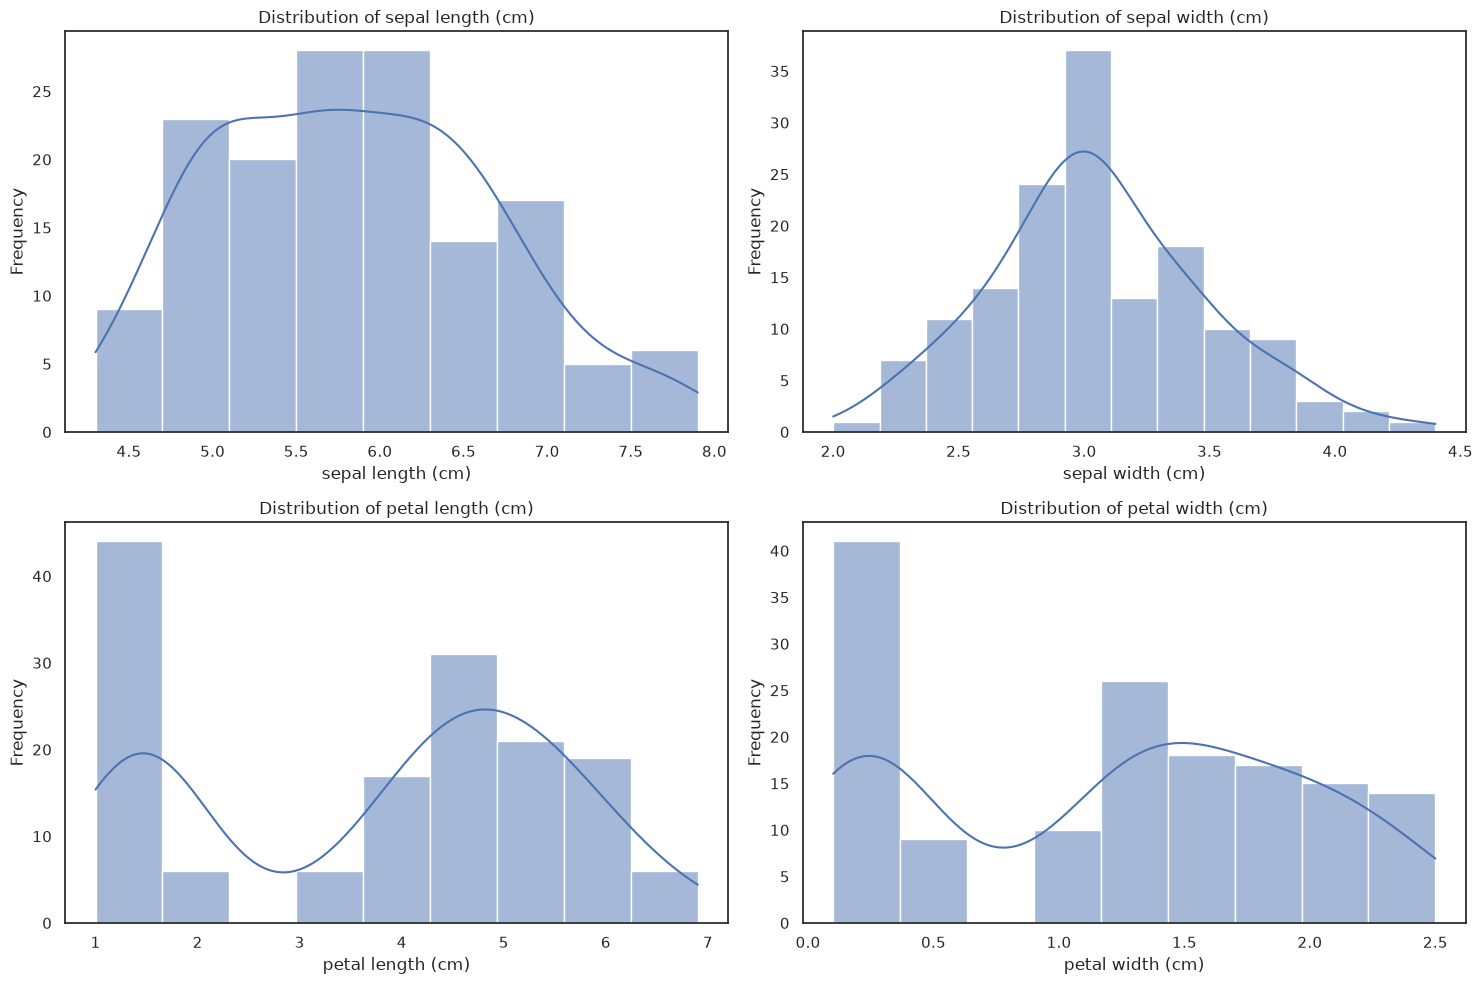

In [16]:
# Get numerical feature names
numerical_features = df_iris.select_dtypes(include=['float']).columns

# Create histograms for each numerical feature
plt.figure(figsize=(15, 10))
for i ,feature in enumerate(numerical_features):
    plt.subplot(2, 2, i+1)
    sns.histplot(df_iris[feature], kde=True)
    plt.title(f'Distribution of {feature}')
    plt.xlabel(feature)
    plt.ylabel('Frequency')
plt.tight_layout()


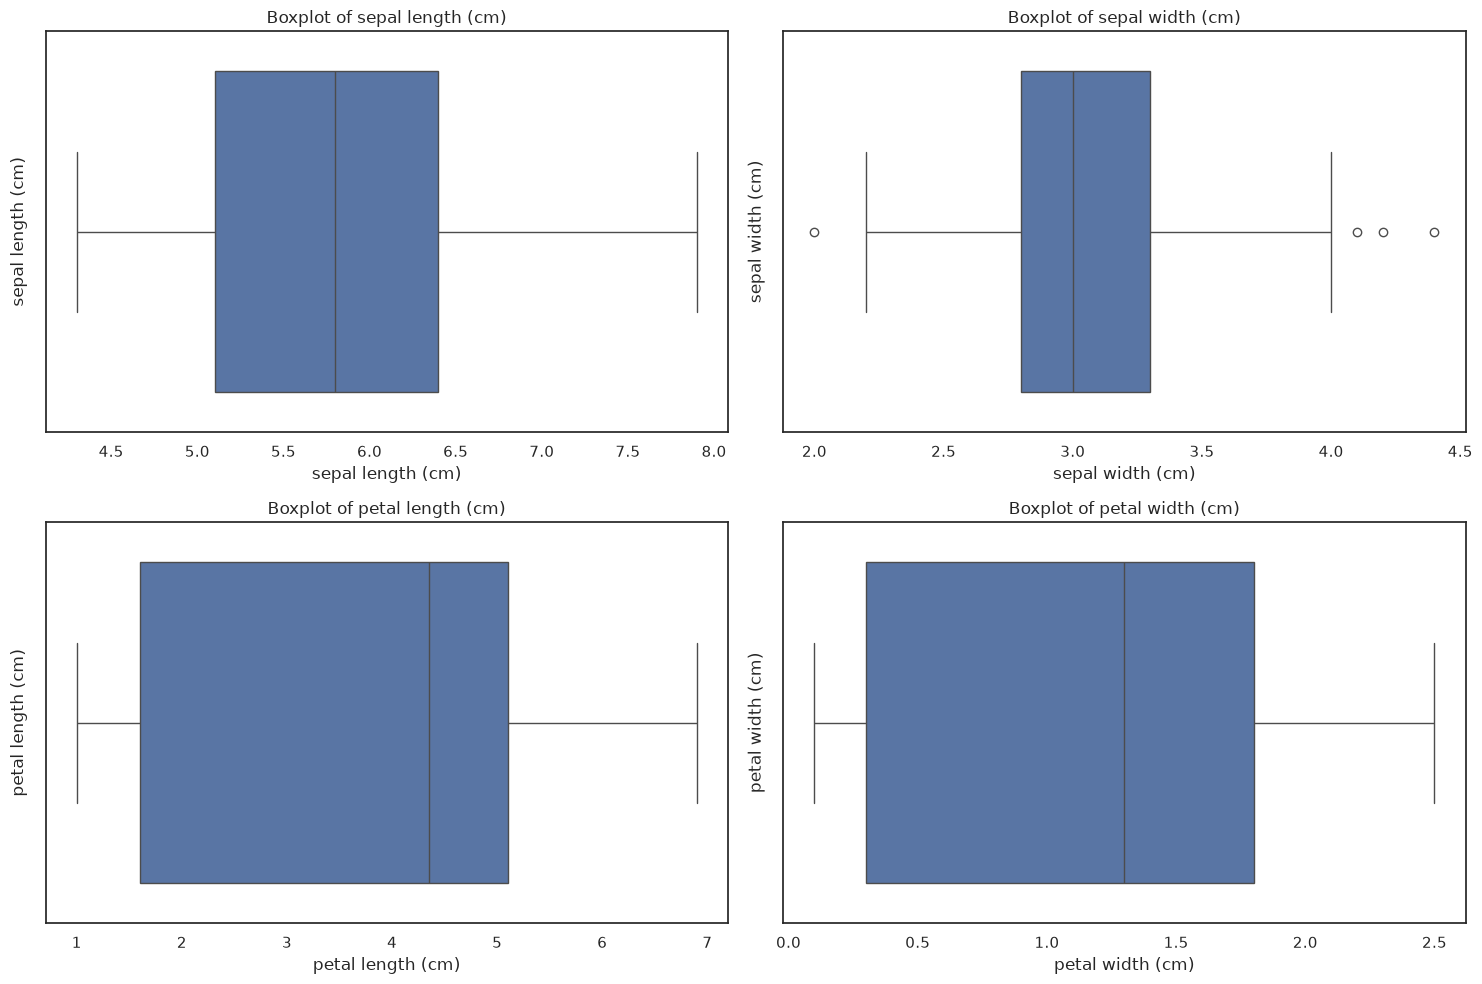

In [18]:
plt.figure(figsize=(15,10))
for i , feature in enumerate(numerical_features):
    plt.subplot(2,2,i+1)
    sns.boxplot(x=df_iris[feature])
    plt.title(f'Boxplot of {feature}')
    plt.ylabel(feature)
plt.tight_layout()

Generating pair plot to visualize feature relationships


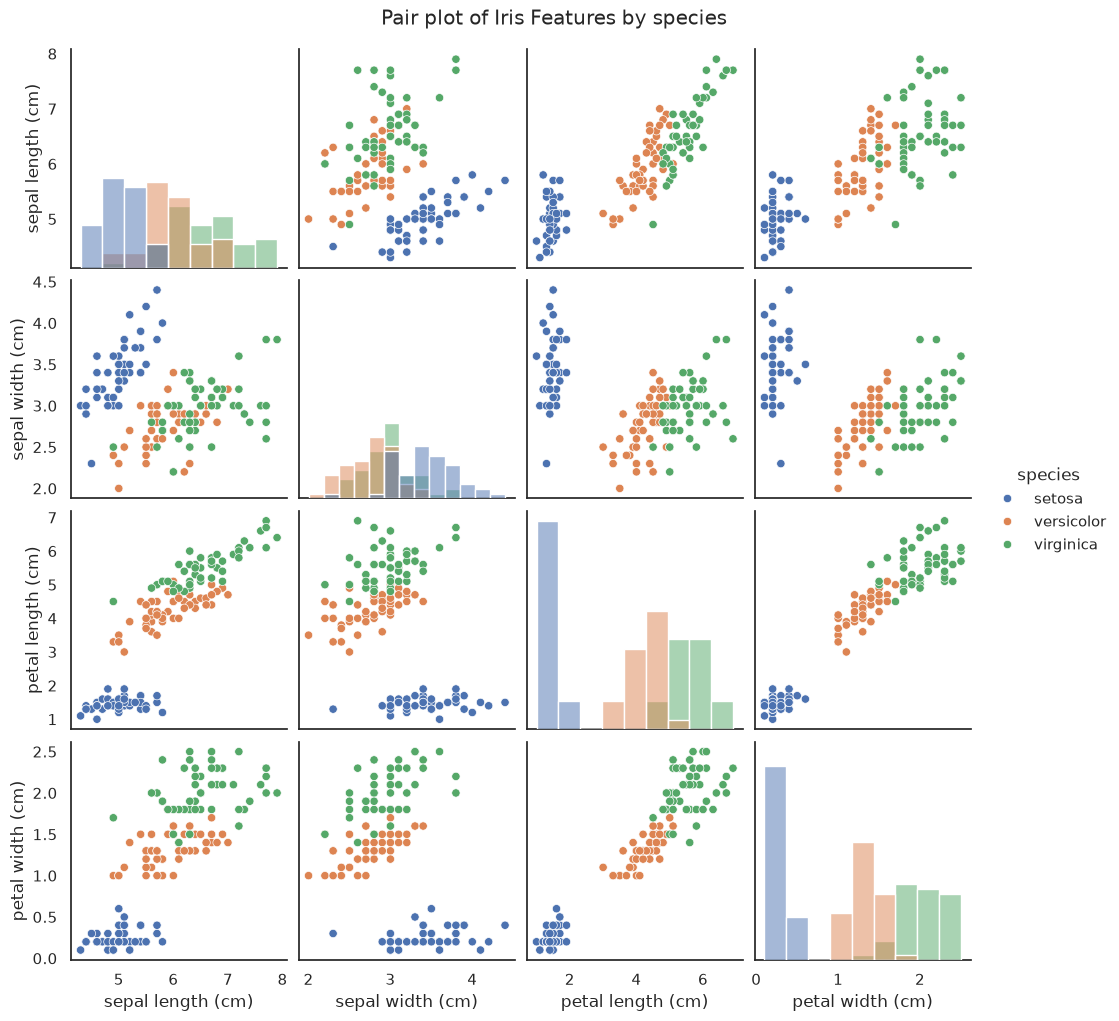

In [19]:
print("Generating pair plot to visualize feature relationships")
sns.pairplot(df_iris, hue='species', diag_kind='hist')
plt.suptitle('Pair plot of Iris Features by species', y=1.02)
plt.show()

In [20]:
from sklearn.model_selection import train_test_split

X = df_iris[['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']]
y = df_iris['species']

In [34]:
# Splitting the dataset into trainnig and testing sets
X_train , X_test , y_train , y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [35]:
from sklearn.tree import DecisionTreeClassifier

dtree_classifier = DecisionTreeClassifier(max_depth=3 ,criterion='entropy', random_state=42 )

# Train the model using the trainnig data
dtree_classifier.fit(X_train, y_train)
print('Decision tree classifier trained successfully.')

Decision tree classifier trained successfully.


In [36]:
from sklearn.metrics import accuracy_score, precision_score,recall_score, f1_score

# Make prediction on the test data
y_pred = dtree_classifier.predict(X_test)

In [37]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average='weighted')
recall = recall_score(y_test, y_pred, average='weighted')
f1 = f1_score(y_test, y_pred, average='weighted')

# Print the metrics
print(f"Model Accuracy: {accuracy:.4f}")
print(f"Model Precision (weighted): {precision:.4f}")
print(f"Model Recall (weighted): {recall:.4f}")
print(f"Model F1-score (weighted): {f1:.4f}")

Model Accuracy: 0.9778
Model Precision (weighted): 0.9794
Model Recall (weighted): 0.9778
Model F1-score (weighted): 0.9777


In [38]:
from sklearn.metrics import confusion_matrix

# Calculate the confusion matrix
conf_matrix = confusion_matrix(y_test,y_pred)

# Get the unique class labels from y_test to label the confusion matrix
class_labels = y_test.unique()
class_labels.sort()



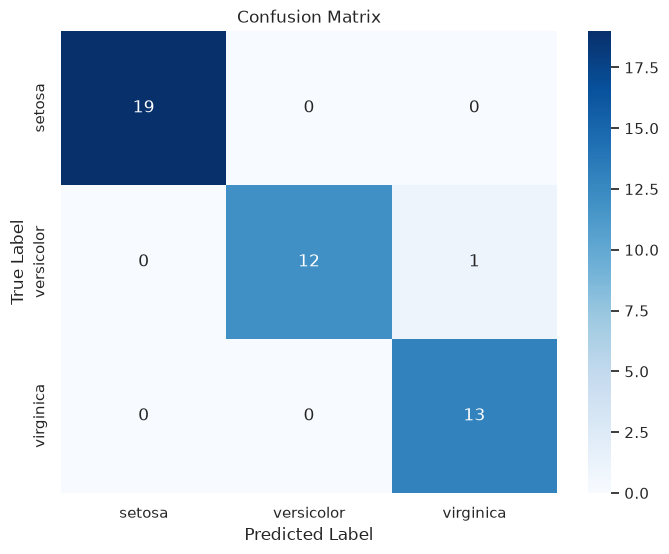

In [39]:
plt.figure(figsize=(8,6))
sns.heatmap(conf_matrix,annot=True, fmt='d', cmap='Blues', xticklabels=class_labels, yticklabels=class_labels)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

Text(0.5, 1.0, 'Decision Tree Visualization')

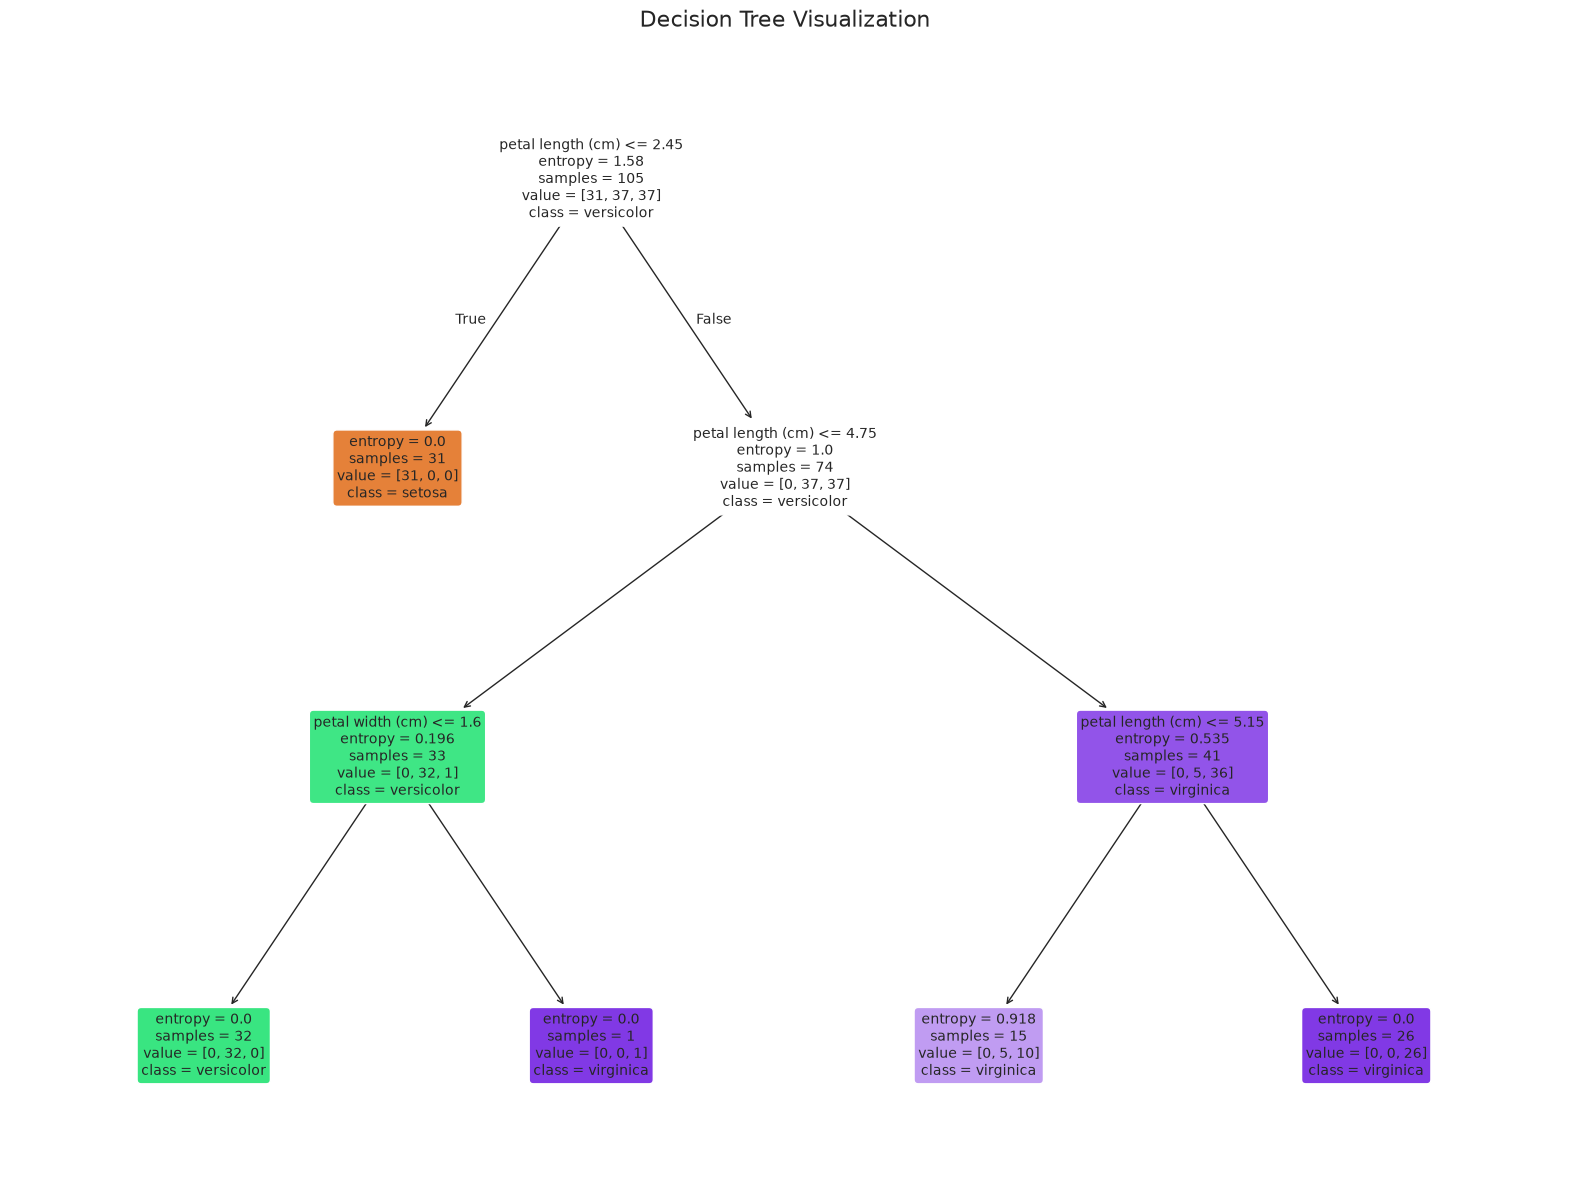

In [40]:
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 15))

plot_tree(
    dtree_classifier,
    feature_names=X.columns,
    class_names=dtree_classifier.classes_,
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title('Decision Tree Visualization', fontsize=16)
